NameError: name 'sqrt' is not defined

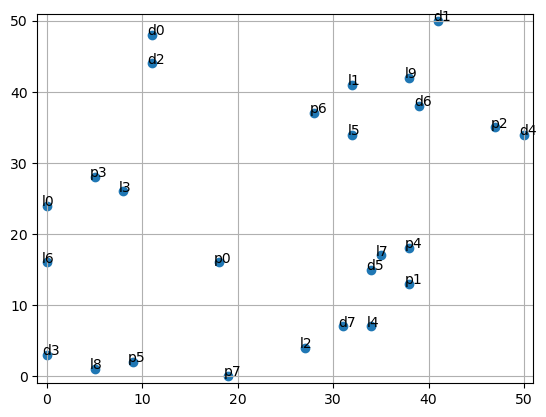

In [ ]:
#!/usr/bin/env python
# coding: utf-8

# In[1]:


import numpy as np
# import networkx as nx
import random
import math
from matplotlib import pyplot as plt
from gurobipy import *
from itertools import product
get_ipython().run_line_magic('matplotlib', 'inline')


# In[2]:

# NOTE: This code can produce subtours if nodes are located at the same location and the pickup times or delivery times are equal to zero. In practice, this may rarely happen

# Seed number(s) for reproducibility
random.seed(1980)

# Parameters

GR = 50 # grid size GRxGR

T = 600 # planning horizon length
W = 60 # time window
b = 120 # block length for drivers

#NOTE: Code currently assumes that T is an integer multiple of b
num_blocks = T / b
assert num_blocks - math.floor(num_blocks) <= 10e-6, "Number of blocks T/b not integer"
num_blocks = int(num_blocks)    # convert it to integer after asserting that it is

num_com_drivers = 5 # number of committed drivers
num_occ_drivers = np.random.poisson(0.4 * T/W) # number of occasiaonal drivers during the whole planning period
num_drivers = num_occ_drivers + num_com_drivers

com_driver_set = list(range(num_com_drivers))
occ_driver_set = list(range(num_com_drivers, num_drivers))

num_requests = 8

# imag_src = [(0,0)] # imaginary depot for all drivers to start from
# imag_delay_src = [0] # imaginary delay at source

# imag_dest = [(10,10)] # imaginary destination added as last destination to guarantee all destinations are visited 
# imag_delay_dest = [0] # imaginary delay at destination

drivers_l0 = [] # drivers' initial locations
delays_l0 = [] # delays for drivers' initial locations
pickups = [] # pickup points
destinations = [] # destination points
delays_p = [] # delays/service times at pickup points
delays_d = [] # delays/service times at destination points

# Append the location of committed drivers first
#NOTE: Location of committed drivers should be decided in the 1st stage
for i in com_driver_set:
    drivers_l0.append((random.randint(0, GR),random.randint(0, GR)))
    delays_l0.append(0)

# Append the location of occasional drivers next
# The occasional drivers location chosen randomly
for i in occ_driver_set:
    drivers_l0.append((random.randint(0, GR),random.randint(0, GR)))
    delays_l0.append(0)

for i in range(num_requests):
    pickups.append((random.randint(0, GR),random.randint(0, GR)))
    destinations.append((random.randint(0, GR),random.randint(0, GR)))
    delays_p.append(0.1 * random.randint(1, 3)) # delay/service time at pickup point 
    delays_d.append(0.2 * random.randint(1, 3)) # delay/service time at dest point

# List of all points
# allpoints = imag_src + drivers_l0 + pickups + destinations + imag_dest # 1st part for pickups and second for destinations
allpoints = drivers_l0 + pickups + destinations # drivers, then pickups, then destinations

# List of all delays
# alldelays = imag_delay_src + delays_l0 + delays_p + delays_d + imag_delay_dest
alldelays = delays_l0 + delays_p + delays_d

# Compute key parameters of MIP model formulation
num_drivers = len(drivers_l0)
num_delays_l0 = len(delays_l0)

# Check if input dimensions match
assert num_drivers == num_delays_l0, 'Number of drivers and delays do not match.'

num_pickups = len(pickups)
num_destinations = len(destinations)
num_points = len(allpoints)
cart_prod = list(product(range(num_points),range(num_points))) # tuples of all nodes
cart_prod_pickups_destinations = list(product(range(num_drivers, num_points), range(num_drivers, num_points))) # tuples of pickups and destinations only
cart_prod_points_drivers = list(product(range(num_drivers, num_points),range(num_drivers))) # tuples of all points and drivers (i, d)
#cart_prod_allpoints_drivers = list(product(range(num_points),range(num_drivers))) # tuples of all points and drivers (i, d)


# Lists (sets) of indices for re-use later and better readability
driver_set = list(range(num_drivers))
pickup_set = list(range(num_drivers, num_drivers + num_pickups))
dest_set = list(range(num_drivers + num_pickups, num_points))
pickup_and_dest_set = list(range(num_drivers, num_points))
all_points_set = list(range(num_points))


# In[3]:


# For visualization, we make annotations to be added to the scatter plot 
annot = list(all_points_set) # label of nodes
cannotlist = list(all_points_set) # completion time of points from solver 

# annot[0] = "IS" # imaginary source node 

for i in driver_set:
    annot[i] = "l" + str(i) # initial location of driver

for i in range(num_pickups):
    annot[i + num_drivers] = "p" + str(i) # pickup point
    
for i in range(num_destinations):
    annot[i + num_drivers + num_pickups] = "d" + str(i) # destination point
    
# annot[-1] = "Fd" # final imaginary destination

# print(annot)
# print(cannotlist)


# In[4]:


xa, ya = zip(*allpoints)
#xa = list(map(lambda x: x[0], allpoints))
#ya = list(map(lambda x: x[1], allpoints))
#print(xa,ya)

fig, ax = plt.subplots()
#ax.scatter(current_loc[0],current_loc[1]) #initial position
#ax.annotate('l0', (current_loc[0]+0.05,current_loc[1]+0.05)) # label the initial point

ax.scatter(xa[0:num_points], ya[0:num_points])
ax.set_xlim([-1, max(xa[0:num_points]) + 1])
ax.set_ylim([-1, max(ya[0:num_points]) + 1])
ax.grid(True)

#Add annotation to the scattered points
for i, txt in enumerate(annot[:]):
    #ax.annotate(txt, (xa[i]+0.09, ya[i]))
    ax.annotate(annot[i], (xa[i] - 0.5, ya[i]))


# In[5]:


# This function determines the Euclidean distance between any two locations/points
def compute_euclidean(loc1, loc2):
    dx = loc1[0] - loc2[0]
    dy = loc1[1] - loc2[1]
    return math.sqrt((dx * dx) + (dy * dy))

#def compute_distance(loc1, loc2):
#    dx = loc1[0] - loc2[0]
#    dy = loc1[1] - loc2[1]
#    return np.sqrt(dx*dx + dy*dy)

### COMPUTING TRAVEL TIMES
# Large travel time/distance value
PD = 0 # penalty distance to avoid starting many drivers

# Compute costs or travel times
distance = {(i, j): compute_euclidean(allpoints[i], allpoints[j]) for (i, j) in cart_prod}

# Travel time from a driver to a pickup node is increased by PD to minimize the number of drivers used since we are minimizing the total distance
for i in driver_set:
    for j in pickup_set:
        distance[i,j] = distance[i,j] + PD
            
### SETTING TIME WINDOWS
# e and l for drivers
# Given a matrix with a string of 1's and 0's for every block in which a driver can be available in (row = driver, column = block), then we can use this to convert it into a time window for the driver
availability_matrix = np.zeros((num_drivers, num_blocks))

# Generate random data for this matrix -- generate a start point for the ones and an end point after it
e = []
l = []
for driver in com_driver_set:
    start_of_ones = random.randint(0, num_blocks - 1)
    end_of_ones = random.randint(start_of_ones, num_blocks - 1)
    availability_matrix[driver, start_of_ones:end_of_ones + 1] = 1
    # Set the time windows accordingly
    e.append(b * start_of_ones)
    l.append(b * (end_of_ones + 1))

# Assumed occasional will work for an hour and they show up at any point in time
#NOTE: We could assume that occasioanl have a higher probability of showing up during peak times
#NOTE: We could also make their length variable later
for driver in occ_driver_set:
    t_start = random.randint(0, T - W)
    e.append(t_start)
    l.append(t_start + W) # occasional drivers are working for for fixed window time. I think this can be randomized.

#l = e.copy()

# Setting e and l for pickups
for i in pickup_set:
    emax = round(T - distance[i,i+num_pickups] - alldelays[i+num_pickups], 0)
    e.append(random.randint(0, emax)) # randomly choose e in this range
    l.append(e[i] + W)
    
# Setting e and l for destinations
for i in dest_set:
    e.append(e[i-num_pickups] + distance[i - num_pickups,i]) # chosen using Ropke and Coudreau paper PDP TW
    l.append(e[i] + W)

# A pickup node can be assigned to driver if its lateness time and earliest time of it destination is within the time window of driver
# z_UB is used for fixation to limit the search space
z_UB = {(pickup,driver): (1 if (l[pickup] - alldelays[pickup] >= e[driver] and l[driver] >= e[pickup + num_pickups] + alldelays[pickup + num_pickups]) else 0) for driver in driver_set for pickup in pickup_set} #cart_prod_pickups_destinations

# Limit on x_UB_{ij} is an upper bound on variable x_{ij}: if e_i + t_{ij} + d_j - l_j > 0 (d_j is delay at j), then x_UB_{ij} = 0; otherwise it is 1
x_UB = {(i,j): (0 if (e[i] + distance[i, j] - PD * (i in driver_set and j in pickup_set) + alldelays[j] > l[j] ) else 1) for (i,j) in cart_prod} #cart_prod_pickups_destinations
## Defining M_{ij}
big_M  = {(i,j): l[i] - e[j] + alldelays[j] + distance[i,j] - PD * (i in driver_set and j in pickup_set) for (i,j) in cart_prod}
## Defining Max_{i} repsenting the largest distance from i to other nodes 
Max_d = {i: max(distance[i,j] for j in pickup_and_dest_set) for i in pickup_and_dest_set}


#Add cost factors for the committed and occasional drivers
c_com_h = 0.4 # fixed cost for committed driver per hour this includes wasted time in traffic jams 
c_com_d = 0.2 # cost paid to committed driver per unit distance including all travelled distance 
# from initial drivers location to first pickup point this makes sense as the platform gives advice 
# on initial drivers location

c_occ_o = 0.5 # fixed cost paid to occasional driver per order if driver is taking k order in a trip total cost will be k times
c_occ_d = 0.2 # cost paid to occasional driver per unit distance excluding distance from driver location to 1st pickup. This first mile drive 
# is influenced by driver decision and not platform. 
# c_occ_h = 0.05 # cost paid to occasional driver per hour to include time in traffic jams. I feel this is not needed as the driver 
# will have the incentive to increase travel time to earn more which can increase the lateness
rev_order = 100 # rev per order

# In[6]:

m = Model()

m.Params.timeLimit = 50.0

### DECISION VARIABLES
# Original variables from model x_{ij}
x = m.addVars(cart_prod, vtype=GRB.BINARY, name="x") # link i to j used
# New variables z_{id} which enables us to set early and late times for the drivers
z = m.addVars(cart_prod_points_drivers, vtype=GRB.BINARY, name="z") # driver ID of node i
# New variables added to separate the travelled distance by committed from occasional drivers
w = m.addVars(cart_prod_points_drivers, vtype=GRB.CONTINUOUS, name="w") # distance of node i to next node in the trip done by driver

# Delta variables for linearization of constraints involving z_{id}
delta_plus = m.addVars(cart_prod_points_drivers, vtype=GRB.BINARY, name="delta_+") # driver ID of node i
delta_minus = m.addVars(cart_prod_points_drivers, vtype=GRB.BINARY, name="delta_-") # driver ID of node i
#delta_00 = m.addVars(cart_prod_points_drivers, vtype=GRB.BINARY, name="delta_0") # driver ID of node i

c = m.addVars(num_points, lb=0, vtype=GRB.CONTINUOUS, name="c") # completion time of each point/node
v = m.addVars(num_points, lb=0, vtype=GRB.CONTINUOUS, name="v") # route index assigned to single vehicle
cmax = m.addVar(lb=0,vtype=GRB.CONTINUOUS, name="cmax") # maximum completion time
#cf = m.addVar(lb=0,vtype=GRB.CONTINUOUS, name="cf")

m.update()

### CONSTRAINTS
# ## c_{max} constraint
# m.addConstrs((cmax >= c[i] for i in all_points_set), name="Max C") # c_{max} >= c_i

## Each node should be visited and left (except for drivers and destinations)
# Links in - Constraint 2 in Furtado et al
m.addConstrs((quicksum(x[i,j] for i in all_points_set) <= 1 for j in pickup_and_dest_set),name="linkstonode==1 except for drivers")
# Links out - Constraint 3 in Furtado et al (with more details/cases here)
m.addConstrs((quicksum(x[driver,j] for j in all_points_set) <= 1 for driver in driver_set),name="linksoutdrivers<=1")
m.addConstrs((quicksum(x[pickup,j] for j in all_points_set) <= 1 for pickup in pickup_set),name="linksoutpickups==1")
m.addConstrs((quicksum(x[dest,j] for j in all_points_set) <= 1 for dest in dest_set),name="linksoutdestination<=1")

## C_j >= C_i + t_ij - M(1 - x_ij) - Constraints 4 in Furtado et al
#m.addConstrs((c[driver] == 0 for driver in driver_set), name="completion time for img source and drivers is 0")
# NOTE/TODO: I think the penalty distance (PD) to start many drivers is unnecessary in our formulation/implementation; so these two constraints can be merged
m.addConstrs((c[j] >= c[i] + alldelays[j] + distance[i,j] - big_M[i, j] * (1 - x[i,j]) for i in pickup_and_dest_set for j in pickup_and_dest_set), name="Completion time")
m.addConstrs((c[j] >= c[driver] + alldelays[j] + distance[driver,j] - PD  - big_M[driver,j] * (1 - x[driver,j]) for driver in driver_set for j in pickup_and_dest_set), name="Completion time for 1st node in route")
# Constraints 8 in Furtado et al
m.addConstrs((c[pickup + num_pickups] >= c[pickup] + alldelays[pickup + num_pickups] + distance[(pickup,pickup + num_pickups)] for pickup in pickup_set), name="pickups must be completed before deliveries")

## Time window constraints - Constraints 6 in Furtado et al
m.addConstrs((c[i] >= e[i] for i in pickup_and_dest_set), name="completion time after early time")
m.addConstrs((c[i] <= l[i] for i in pickup_and_dest_set), name="completion time before late time")

## NEW: Node's completion time should be within the driver's time window (if driver visits that node)
m.addConstrs((c[i] <= quicksum(l[d] * z[i,d] for d in driver_set) for i in pickup_and_dest_set), name="completion time before driver late time")
m.addConstrs((c[i] >= quicksum(e[d] * z[i,d] for d in driver_set) for i in pickup_and_dest_set), name="completion time after driver early time")

## v constraints
#NOTE: In Furtado et al, the index of the route is that of the first pickup point the driver visits (infinite # of drivers are assumed at the depot); since in the worst case, each pickup would be handeled by a single driver, their "big-M" for this constraint is the number of requests n. In our case, the indices of the pickup points start from num_drivers so we have to add that to num_pickups to achieve the same result

# Constraints 10 and 11 in Furtado et al (similar though not exactly the same)
m.addConstrs((v[driver] == driver for driver in driver_set), name="driver's index") # labeling or numbering initial location of drivers (these numbers are the route/driver numbers)

# m.addConstrs((v[j] >= driver * x[driver,j] for j in pickup_and_dest_set for driver in driver_set), name="index of route is equal to index of vehicle assigned to")
# m.addConstrs((v[j] <= driver * x[driver,j] - (num_drivers + 1) * (x[driver,j] - 1) for j in pickup_and_dest_set for driver in driver_set), name="index of route is equal to index of vehicle assigned to")

# m.addConstrs((v[j] >= v[i] + (num_drivers + 1) * (x[i,j] - 1) for i in pickup_and_dest_set for j in pickup_and_dest_set), name="nodes on same route have same route index")
# m.addConstrs((v[j] <= v[i]- (num_drivers + 1) * (x[i,j] - 1) for i in pickup_and_dest_set for j in pickup_and_dest_set), name="nodes on same route have same route index")

# Constraints 9 in Furtado et al
m.addConstrs((v[pickup + num_pickups] == v[pickup] for pickup in pickup_set), name="pickup and delivery are in the same route")

# Constraints 12 and 13 in Furtado et al
m.addConstrs((v[j] >= v[i] + (num_drivers + 1) * (x[i,j] - 1) for i in all_points_set for j in all_points_set), name="nodes on same route have same route index")
m.addConstrs((v[j] <= v[i] - (num_drivers + 1) * (x[i,j] - 1) for i in all_points_set for j in all_points_set), name="nodes on same route have same route index")
# This constraint is added to guarantee that if v_i = v_j then x[i,j]=1


## NEW: New constraints for the linearization of: 1 - z_{id} = max{|vi-d|,1}
m.addConstrs((v[i] - driver >= 1 - (num_points + 1) * (1 - delta_plus[i, driver]) for i in pickup_and_dest_set for driver in driver_set), name="1.")
m.addConstrs((v[i] - driver <= num_points * (delta_plus[i, driver] + delta_minus[i,driver]) for i in pickup_and_dest_set for driver in driver_set), name="2.")
m.addConstrs((v[i] - driver >= -num_points * (delta_plus[i,driver] + delta_minus[i,driver]) for i in pickup_and_dest_set for driver in driver_set), name="3.")
m.addConstrs((v[i] - driver <= -1 + (num_points + 1) * (1 - delta_minus[i,driver]) for i in pickup_and_dest_set for driver in driver_set), name="4.")
m.addConstrs((1 - delta_plus[i,driver] - delta_minus[i,driver] <= z[i,driver] for i in pickup_and_dest_set for driver in driver_set), name="5.")
m.addConstrs((delta_plus[i,driver] + delta_minus[i,driver] <= 1 - z[i,driver] for i in pickup_and_dest_set for driver in driver_set), name="6.")
#m.addConstrs((delta_plus[i,d] + delta_minus[i,d] + delta_0[i,d] == 1 for i in pickup_and_dest_set for driver in driver_set), name="7.") #  Not needed 

## Variable fixations to speed up the run time as described in Section 4 of Furtado et al
m.addConstrs((x[i,i] == 0 for i in all_points_set), name="xii==0") # no self-loops
m.addConstrs((x[i,driver] == 0 for i in pickup_and_dest_set for driver in driver_set) ,name="no link to drivers")
#m.addConstrs((x[num_points-1, i] == 0 for i in all_points_set),name="no link out final destination zero") 
#m.addConstrs((x[pickup, num_points-1] == 0 for pickup in pickup_set) , name = "no link from pickup to final destination")
m.addConstrs((x[pickup+num_pickups,pickup] == 0 for pickup in pickup_set), name="no link from destination to its pickup")
m.addConstrs((x[driver,dest] == 0 for driver in driver_set for dest in dest_set), name="no link from drivers to destinations")
m.addConstrs((x[i,j] <= x_UB[i,j] for i in all_points_set for j in all_points_set),name="no link from i to j is x_UB_ij is zero")
#m.addConstrs((x[driver,j] <= x_UB[driver,j] for driver in driver_set for j in pickup_and_dest_set),name="no link from i to j is x_UB i j is zero")
m.addConstrs((x[driver,driver] == 0 for driver in driver_set for driver in driver_set),name="no link btw drivers")

m.addConstrs((z[pickup,driver] <= z_UB[pickup,driver] for driver in driver_set for pickup in pickup_set), name="feasibility of driver to a node")
m.addConstrs((z[dest,driver] <= z_UB[dest-num_pickups,driver] for driver in driver_set for dest in dest_set), name="feasibility of driver to a node")

## constriants on w[i,driver] give the distance from i in pickup or destination set to next node on route if it done by driver and 0 for remaining drivers
m.addConstrs((w[i,driver] <= quicksum(distance[i,j]*x[i,j] for j in pickup_and_dest_set) + Max_d[i]*(1-z[i,driver]) for driver in driver_set for i in pickup_and_dest_set), name="w_i,d<=x_i,j")
m.addConstrs((w[i,driver] >= quicksum(distance[i,j]*x[i,j] for j in pickup_and_dest_set) - Max_d[i]*(1-z[i,driver]) for driver in driver_set for i in pickup_and_dest_set), name="w_i,d<=x_i,j")
m.addConstrs((w[i,driver] <= Max_d[i]*z[i,driver] for driver in driver_set for i in pickup_and_dest_set), name="w_i,d<=z_i,d")

#m.addConstrs((w[i,driver] <= x[i,j] for driver in driver_set for i in pickup_and_dest_set for j in pickup_and_dest_set), name="w_i,d<=x_i,j")
#m.addConstrs((w[i,driver] <= z[i,driver] for driver in driver_set for i in pickup_and_dest_set), name="w_i,d<=z_i,d")
#m.addConstrs((w[i,driver] >= z[i,driver]+x[i,j]-1 for driver in driver_set for i in pickup_and_dest_set for j in pickup_and_dest_set), name="w_i,d >= x_i,j + z_i,d -1")

# Total cost paid for committed drivers for commitment to work during the 'blocks', these will be constant in the 2nd 
# stage as they are decided on in the first stage. We include them here to have full picture on cost  
c_com_hour_obj = c_com_h*quicksum(l[driver]-e[driver] for driver in com_driver_set)

# Total cost paid to committed drivers for travelled distance 
c_com_dist_obj = c_com_d*quicksum(w[i,driver] for i in pickup_and_dest_set for driver in com_driver_set)
# for a committed driver we need to add the distance from their initial location to the first pickup point
# this makes sense as the platform gives advice on initial drivers location in the first stage (platform decision)
c_com_dist_obj = c_com_dist_obj + c_com_d*quicksum(distance[driver,i]*x[driver,i] for i in pickup_and_dest_set for driver in com_driver_set)

# Total cost paid to occasional drivers for travelled distance, here we don't include the cost from initial 
# location to first pickup as the driver is free to start wherever he wants (driver decision).   
c_occ_dist_obj = c_occ_d*quicksum(w[i,driver] for i in pickup_and_dest_set for driver in occ_driver_set)

# Total fixed cost paid to occasional drivers for the 'orders' served
c_occ_order_obj = c_occ_o*quicksum(z[i,driver] for i in pickup_set for driver in occ_driver_set)

# Total revenue generated from serving the orders
rev_order_obj = rev_order*quicksum(z[i,driver] for i in pickup_set for driver in driver_set)

### OBJECTIVE FUNCTION
obj = rev_order_obj - (c_com_hour_obj + c_com_dist_obj +  c_occ_dist_obj + c_occ_order_obj) # +  quicksum(distance[i,j] * x[i,j] for (i,j) in cart_prod)
#obj =  quicksum(distance[i,j] * x[i,j] for (i,j) in cart_prod)

m.setObjective(obj, GRB.MAXIMIZE) 

m.update()

m.optimize()



In [ ]:
node = 10
print(m.getVarByName("v["+str(node)+"]"))
for i in all_points_set:
    print(m.getVarByName("x["+str(node)+","+str(i)+"]"))  

<gurobi.Var v[10] (value 1.0000000000001732)>
<gurobi.Var x[10,0] (value 0.0)>
<gurobi.Var x[10,1] (value 0.0)>
<gurobi.Var x[10,2] (value 0.0)>
<gurobi.Var x[10,3] (value 0.0)>
<gurobi.Var x[10,4] (value 0.0)>
<gurobi.Var x[10,5] (value 0.0)>
<gurobi.Var x[10,6] (value 0.0)>
<gurobi.Var x[10,7] (value 0.0)>
<gurobi.Var x[10,8] (value 0.0)>
<gurobi.Var x[10,9] (value 0.0)>
<gurobi.Var x[10,10] (value 0.0)>
<gurobi.Var x[10,11] (value 0.0)>
<gurobi.Var x[10,12] (value 0.0)>
<gurobi.Var x[10,13] (value 0.0)>
<gurobi.Var x[10,14] (value 0.0)>
<gurobi.Var x[10,15] (value 0.0)>
<gurobi.Var x[10,16] (value 1.0)>
<gurobi.Var x[10,17] (value 0.0)>
<gurobi.Var x[10,18] (value 0.0)>
<gurobi.Var x[10,19] (value 0.0)>
<gurobi.Var x[10,20] (value 0.0)>
<gurobi.Var x[10,21] (value 0.0)>
<gurobi.Var x[10,22] (value 0.0)>
<gurobi.Var x[10,23] (value 0.0)>


0
1
2
3
4
5
6
7
8
2
2
1
1
1
2
4
4
2
2
1
1
1
2
4
4


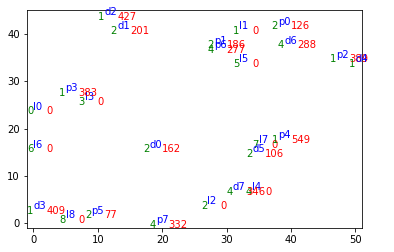

In [ ]:
# In[9]:

#for i in all_points_set:
    #        print(annot[19])
    #print(m.getVarByName("v["+str(i)+"]"))     
    #print(m.getVarByName("xij["+str(i)+",29"+"]"))        


# In[10]:

fig, ax = plt.subplots()

#ax.scatter(xa[0:num_points-1], ya[0:num_points-1])
ax.set_xlim([-1, max(xa[0:num_points])+1])
ax.set_ylim([-1, max(ya[0:num_points])+1])
#ax.grid(True)
#colorVal = scalarMap.to_rgba(num_points-1)

cmap = plt.get_cmap('gnuplot')
colors = [cmap(i) for i in np.linspace(0, 1, num_points)]

for i in all_points_set:
    c_sol = m.getVarByName("c["+str(i)+"]")
    v_sol = m.getVarByName("v["+str(i)+"]")
      
    for j in all_points_set:
        x_sol = m.getVarByName("x["+str(i)+","+str(j)+"]")
        #print(x_sol.X)
        if abs(x_sol.X - 1) <= 10e-4:            
            u = allpoints[i]
            vx = allpoints[j][0] - allpoints[i][0]
            vy = allpoints[j][1] - allpoints[i][1]
            if abs(vx) + abs(vy) >= 0.0:
                ax.arrow(u[0], u[1], vx, vy, head_width=0.25, length_includes_head=False, color=colors[int(v_sol.X) ])
            #(vix.X/num_requests,0.5,0.25,0.45))  #(v.X/2,0.5,0.5,0.5)
            #shape='full', lw=0, length_includes_head=False, head_width=arwidth

    ax.annotate(annot[i], (xa[i], ya[i]), color='blue')
    ax.annotate(round(c_sol.X), (xa[i]+2, ya[i]-1), color='red')
    ax.annotate(round(v_sol.X), (xa[i]-1, ya[i]-1), color='green')
    #print(round(c_sol.X))
    print(round(v_sol.X))

fig.savefig('solution1.pdf')

In [ ]:
print(round(c_sol.X))
print(annot)
print(distance[12,11])

64
['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'p0', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'd0', 'd1', 'd2', 'd3', 'd4', 'd5', 'd6', 'd7']
23.769728648009426


In [ ]:
#for i in driver_set:
#    print(m.getVarByName("w[11,"+str(i)+"]"))
#    print(m.getVarByName("z[11,"+str(i)+"]"))

c_com_d_obj = 0
c_occ_d_obj = 0
c_occ_o_obj = 0

#for i in pickup_and_dest_set:
#    for driver in com_driver_set:
#        c_com_d_obj = c_com_d_obj + c_com_d*m.getVarByName("w["+str(i)+","+str(driver)+"]").X        
#    for driver in occ_driver_set:
#        c_occ_d_obj = c_occ_d_obj + c_occ_d*m.getVarByName("w["+str(i)+","+str(driver)+"]").X

for i in pickup_set:
    for driver in com_driver_set:
        c_com_d_obj = c_com_d_obj + c_com_d*m.getVarByName("x["+str(driver)+","+str(i)+"]").X*distance[driver,i]
        
#for i in pickup_set:
#    for driver in driver_set:
#        c_occ_o_obj = c_occ_o_obj + c_occ_o*m.getVarByName("z["+str(i)+","+str(driver)+"]").X 
    
print(m.objVal)
print(c_com_hour_obj,c_com_d_obj,c_occ_d_obj,c_occ_o_obj)
print(c_com_hour_obj+c_com_d_obj+c_occ_d_obj+c_occ_o_obj)


193.06223028621923
<gurobi.LinExpr: 576.0> 0.0 0 0
<gurobi.LinExpr: 576.0>


In [ ]:
print(num_com_drivers,num_occ_drivers)

5 7


In [ ]:
### KPIs
nbr_served_orders = 0 # total nbr of served orders in the planning time T 
nbr_served_orders_occ = 0 #total nbr of served orders assigned to occasional drivers in the planning time T 
nbr_com_drivers_utilized = 0 # total nbr of committed drivers utilized (at least with one order assigned) in the planning time T 
nbr_occ_drivers_utilized = 0 # total nbr of occasional drivers utilized (at least with one order assigned) in the planning time T 
avg_utilisation_com_driver = 0 # average utilisation of a committed drivers
work_balance = 0 #To be defined

#nbr_served_orders is computed using z[pickup,driver]
for pickup in pickup_set:
    for driver in driver_set:
        z_sol = m.getVarByName("z["+str(pickup)+","+str(driver)+"]")
        nbr_served_orders +=  z_sol.X

print("Service Level SL: ", nbr_served_orders/num_requests)

#nbr_served_orders_occ is computed using z[pickup,occ_driver]
for pickup in pickup_set:
    for driver in occ_driver_set:
        z_sol = m.getVarByName("z["+str(pickup)+","+str(driver)+"]")
        nbr_served_orders_occ +=  z_sol.X

print("SL due to occasional drivers: ", nbr_served_orders_occ/num_requests)

#nbr_com_drivers_utilized is computed using z[pickup,com_driver]
for driver in com_driver_set:
    for pickup in pickup_set:
        z_sol = m.getVarByName("z["+str(pickup)+","+str(driver)+"]")
        nbr_com_drivers_utilized +=  z_sol.X
        if  abs(z_sol.X-1)<=10e-4:
            break

print("Fraction of com drivers utilized: ", round(nbr_com_drivers_utilized/num_com_drivers,3))


#nbr_occ_drivers_utilized is computed using z[pickup,occ_driver]
for driver in occ_driver_set:
    for pickup in pickup_set:
        z_sol = m.getVarByName("z["+str(pickup)+","+str(driver)+"]")
        nbr_occ_drivers_utilized +=  z_sol.X
        if  abs(z_sol.X-1)<=10e-4:
            break

print("Fraction of occ drivers utilized: ", round(nbr_occ_drivers_utilized/num_occ_drivers,3))

#Missing work balance. We need to define it.

Service Level SL:  1.0
SL due to occasional drivers:  0.0
Fraction of com drivers utilized:  0.4
Fraction of occ drivers utilized:  0.0
